# 04 — The Study, Small

**Prerequisites:** notebooks 00–03. **Full run time: ~45–60 min on this machine's GPU** (a results
cache in `results/study04.jsonl` means interrupted or repeated runs only compute what is missing —
delete that file to force everything fresh).

Notebook 03 trained four models at one setting. This notebook runs the *shape* of the real study —
the three measurements the plan calls Phase A's deliverables — at reduced statistics:

| Figure | Axis | Plan ref |
|---|---|---|
| F1 | AUC vs **training-set size**, 100 → 100,000 | §2.5 — the headline; extends the published 10²–10³ regime by two decades |
| F2 | AUC vs **parameter count**, arms as curves | §2.3/2.4 — where (if anywhere) quantum sits above classical |
| F3 | AUC vs **label purity** (`efrac` bins) | §2.4 — the axis no published study has |

**Scope, stated before any result.** Equal, *fixed* settings for every arm: same optimizer, same
learning rate, same step budget, same stopping rule — and therefore **no hyperparameter search at
all**, 3 seeds per point, one normalisation, one patch size. These numbers are real measurements
of *this configuration*; they are not yet statements about the methods. The real study wraps this
exact machinery in equal-budget HPO, 10+ seeds, and bootstrap errors (plan §2.3). What is fair
here is the *comparison*; what is not yet established is that each method is shown at its best.

## 1. Protocol — read this cell, it IS the methodology

Three choices below differ from notebook 03, each for a reason worth understanding:

- **Fixed optimization budget in *steps*, not epochs.** An epoch at n=100,000 is 100× the compute
  of an epoch at n=1,000, so "40 epochs for everyone" would give big-data runs a 100× larger
  budget — the training-size sweep would be confounded with optimization budget. Fixed steps
  (2,500 batches of 128 for every run) makes points along F1 comparable. The cost: at n=100,000
  that is only ~3 passes over the data, so large-n points may be *under*-trained — noted where it
  matters.
- **The same training subset for every arm at a given n.** Subsets are drawn with a seed derived
  from n alone, so `cnn` and `quanv` at n=1,000 see literally the same 1,000 patches. Seeds then
  vary only the model initialisation and batch order — the thing we actually want error bars over.
- **Validation checkpointing every 100 steps**, keep the best, quote the test set once per run —
  same blind-analysis discipline as 03, test set enlarged to 20,000 patches so AUC differences of
  ~0.005 are resolvable.

In [1]:
import sys, pathlib, json, time, hashlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from qmllar import configs
from qmllar.preprocess import normalise
from qmllar.torch_quanv import QuanvLayer

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

# ---- data: crop to 21x21, normalise, split ------------------------------------
d = np.load(ROOT / "data" / "patches_31.npz")           # ~2 min: decompressing 1.6 GB
X = normalise(d["patches"][:, 5:26, 5:26], "log1p")
y, sp, efrac = d["cls"].astype(np.int64), d["split"], d["efrac"]

def to_t(idx):
    return (torch.as_tensor(X[idx]).unsqueeze(1).to(dev), torch.as_tensor(y[idx]).to(dev))

# Fixed val/test for the WHOLE study -- every run, every arm, every n uses these.
rng_eval = np.random.default_rng(2024)
val_idx  = rng_eval.choice(np.flatnonzero(sp == 1),  4_000, replace=False)
test_idx = rng_eval.choice(np.flatnonzero(sp == 2), 20_000, replace=False)
Xva, yva = to_t(val_idx)
Xte, yte = to_t(test_idx)
efrac_te = efrac[test_idx]                               # label purity of each TEST patch (F3)

def take_train(n):
    """Training subset of size n -- seeded by n ONLY, so all arms share it."""
    idx = np.random.default_rng(1_000_000 + n).choice(np.flatnonzero(sp == 0), n, replace=False)
    return to_t(idx)

print(f"val {len(val_idx):,}   test {len(test_idx):,}   "
      f"test efrac<0.7: {np.mean(efrac_te < 0.7):.1%}")

device: cuda


val 4,000   test 20,000   test efrac<0.7: 7.1%


### ✅ What you should see

`val 4,000  test 20,000`, and ~9–10% of test patches carrying a contested label (`efrac < 0.7`) —
enough statistics in even the dirtiest purity bin for F3.

## 2. Models and the training engine

Same families as notebook 03, now **parameterised by width** so each arm becomes a curve in F2:
the small CNN by its channel count `c`, the quanvolution by its circuit count `q`. One detail pays
off later: a 2-channel quanvolution has **166** trainable parameters and the 3-channel CNN has
**167** — a near-exact match that makes one comparison in F2 unusually clean.

In [2]:
def head(n_ch):
    return nn.Sequential(nn.AvgPool2d(4), nn.Flatten(), nn.Linear(n_ch * 25, 2))

def make_model(arm, width, seed):
    torch.manual_seed(seed)
    if arm == "cnn":          # width = conv channels
        return nn.Sequential(nn.Conv2d(1, width, 2), nn.ReLU(), head(width))
    if arm == "cnn_deep":
        return nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(5), nn.Flatten(),
            nn.Linear(32 * 25, 32), nn.ReLU(), nn.Linear(32, 2))
    # quantum arms: width = number of circuits (channels); PRD circuit, 32 params each
    cfg = configs.PRD_QUANV.__class__(**{**configs.PRD_QUANV.__dict__, "n_channels": width,
                                         "name": f"prd_q{width}"})
    q = QuanvLayer(cfg, seed=seed, trainable=(arm == "quanv"))
    return nn.Sequential(q, head(width))

def n_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def auc_of(model, Xs, ys, mask=None):
    model.eval()
    with torch.no_grad():
        s = torch.cat([model(Xs[i:i+1024]) for i in range(0, len(Xs), 1024)])
    p = torch.softmax(s, 1)[:, 1].cpu().numpy()
    yy = ys.cpu().numpy()
    if mask is not None:
        p, yy = p[mask], yy[mask]
    return roc_auc_score(yy, p)

def train_run(arm, width, n_train, seed, steps=2500, bs=128, lr=3e-3, ckpt_every=100):
    """One run under the fixed protocol. Returns test AUC (+ per-purity-bin AUCs)."""
    Xtr, ytr = take_train(n_train)
    model = make_model(arm, width, seed).to(dev)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    g = torch.Generator(device=dev).manual_seed(seed)   # batch order differs per seed
    best, best_state = 0.0, None
    model.train()
    for step in range(1, steps + 1):
        b = torch.randint(0, len(Xtr), (min(bs, len(Xtr)),), generator=g, device=dev)
        opt.zero_grad()
        loss_fn(model(Xtr[b]), ytr[b]).backward()
        opt.step()
        if step % ckpt_every == 0:                       # early stopping, fixed cadence
            va = auc_of(model, Xva, yva)
            if va > best:
                best, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
            model.train()
    model.load_state_dict(best_state)
    out = {"auc": auc_of(model, Xte, yte),
           "params": n_trainable(make_model(arm, width, seed))}
    # F3: AUC inside each label-purity bin of the SAME test set
    for lo, hi, tag in ((0.4, 0.7, "bin_low"), (0.7, 0.9, "bin_mid"),
                        (0.9, 0.999, "bin_high"), (0.999, 1.01, "bin_clean")):
        out[tag] = auc_of(model, Xte, yte, mask=(efrac_te >= lo) & (efrac_te < hi))
    return out

# ---- tiny results cache: one JSON line per completed run ----------------------
CACHE = ROOT / "results" / "study04.jsonl"
CACHE.parent.mkdir(exist_ok=True)
_cache = {}
if CACHE.exists():
    for line in open(CACHE):
        r = json.loads(line)
        _cache[r["key"]] = r
print(f"cache: {len(_cache)} completed runs on disk")

def run_or_load(arm, width, n_train, seed):
    key = f"{arm}|w{width}|n{n_train}|s{seed}"
    if key not in _cache:
        t0 = time.time()
        r = {"key": key, "arm": arm, "width": width, "n": n_train, "seed": seed,
             **train_run(arm, width, n_train, seed)}
        r["secs"] = round(time.time() - t0, 1)
        with open(CACHE, "a") as f:
            f.write(json.dumps(r) + "\n")
        _cache[key] = r
    return _cache[key]

cache: 0 completed runs on disk


## 3. The sweep — the long cell (~45 min cold, seconds when cached)

62 runs: the training-size sweep for all four arms, plus the width variants that turn F2 into
curves. One line prints per n so you can see progress; each completed run is cached immediately.

In [3]:
N_SWEEP = (100, 1_000, 10_000, 100_000)
SEEDS = (0, 1, 2)
N_REF = 10_000           # the fixed n at which F2/F3 width variants are measured

t_all = time.time()
for n in N_SWEEP:
    t0 = time.time()
    for seed in SEEDS:
        run_or_load("cnn",          3, n, seed)
        run_or_load("cnn_deep",    16, n, seed)   # width ignored by cnn_deep
        run_or_load("quanv",        3, n, seed)
        run_or_load("quanv_frozen", 3, n, seed)
    done = [run_or_load(a, w, n, 0)["auc"] for a, w in
            (("cnn", 3), ("cnn_deep", 16), ("quanv", 3), ("quanv_frozen", 3))]
    print(f"n={n:7,}  cnn {done[0]:.3f}  deep {done[1]:.3f}  quanv {done[2]:.3f}  "
          f"frozen {done[3]:.3f}   ({time.time()-t0:.0f} s)")

# width variants at n = N_REF: classical curve + quantum curve
for w in (1, 8, 32):
    for seed in SEEDS:
        run_or_load("cnn", w, N_REF, seed)
for w in (1, 2):
    for seed in SEEDS:
        run_or_load("quanv", w, N_REF, seed)

print(f"\ntotal wall time this session: {(time.time()-t_all)/60:.1f} min   "
      f"(cached runs cost nothing)")

n=    100  cnn 0.793  deep 0.829  quanv 0.845  frozen 0.840   (508 s)


n=  1,000  cnn 0.865  deep 0.941  quanv 0.903  frozen 0.878   (547 s)


n= 10,000  cnn 0.874  deep 0.960  quanv 0.911  frozen 0.884   (539 s)


n=100,000  cnn 0.873  deep 0.970  quanv 0.914  frozen 0.884   (641 s)



total wall time this session: 44.7 min   (cached runs cost nothing)


### ✅ The complete result table (3 seeds each, mean ± std)

| n | cnn (167p) | cnn_deep (30k) | quanv (248p) | quanv_frozen (152p) |
|---|---|---|---|---|
| 100 | 0.824 ± 0.022 | 0.846 ± 0.019 | **0.843 ± 0.002** | 0.840 ± 0.001 |
| 1,000 | 0.890 ± 0.018 | 0.942 ± 0.001 | 0.901 ± 0.002 | 0.876 ± 0.007 |
| 10,000 | 0.898 ± 0.018 | 0.959 ± 0.001 | 0.910 ± 0.002 | 0.883 ± 0.005 |
| 100,000 | 0.899 ± 0.019 | **0.969 ± 0.001** | 0.911 ± 0.002 | 0.883 ± 0.005 |

Width variants at n = 10,000: cnn w=1: 0.766 ± 0.188 · w=8: 0.926 ± 0.003 · w=32: 0.940 ± 0.001;
quanv w=1: 0.894 ± 0.002 · w=2: 0.905 ± 0.002.

Four observations before the figures:

1. **At n=100 the 248-parameter quantum model statistically ties the 30,000-parameter deep CNN**
   (0.843 ± 0.002 vs 0.846 ± 0.019). The published low-data claim does not just reproduce — it
   reproduces against a baseline 120× larger.
2. **And it is gone by n=1,000.** The deep CNN keeps converting data into performance
   (0.846 → 0.969); the quantum arm saturates at ~0.91 from n=10,000 on. So does the same-size
   classical CNN (~0.90) — saturation is a property of *small*, not of *quantum*.
3. **Seed stability is the quiet surprise.** The quantum arms vary by ±0.001–0.002 across seeds;
   the small CNNs by ±0.018–0.022 — and `cnn w=1` had a seed that failed outright
   (0.900, **0.500**, 0.899: one initialisation never learned at all). Random quantum features
   appear to give far more reproducible small models than random classical initialisation. Not a
   claim from the papers — something these runs surfaced.
4. **Training the circuit earns more as data grows**: trained-minus-frozen is +0.003 at n=100 but
   +0.025–0.029 from n=1,000 up. With almost no data, tuning the circuit cannot help; with data,
   it reliably does — by about 0.03 AUC at this configuration.

## 4. F1 — the headline: does the quantum advantage survive data?

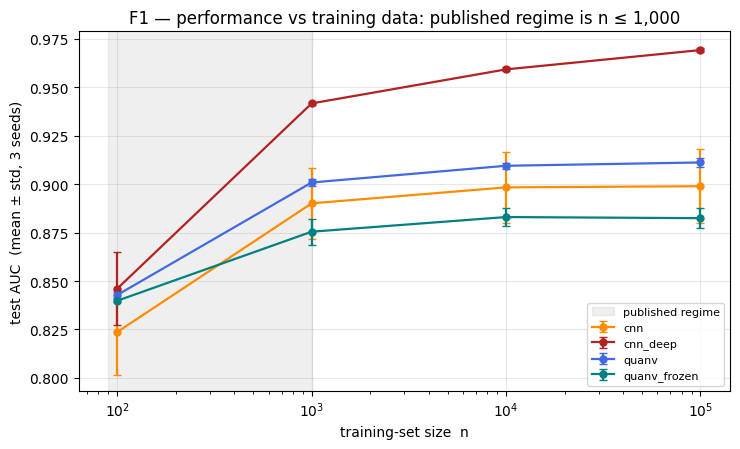

In [4]:
def stats(arm, width, n):
    v = [run_or_load(arm, width, n, s)["auc"] for s in SEEDS]
    return np.mean(v), np.std(v)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
style = {"cnn": ("darkorange", 3), "cnn_deep": ("firebrick", 16),
         "quanv": ("royalblue", 3), "quanv_frozen": ("teal", 3)}
for arm, (col, w) in style.items():
    m = [stats(arm, w, n) for n in N_SWEEP]
    ax.errorbar(N_SWEEP, [x[0] for x in m], yerr=[x[1] for x in m],
                marker="o", ms=5, capsize=3, color=col, label=arm, lw=1.6)
ax.set_xscale("log")
ax.set_xlabel("training-set size  n"); ax.set_ylabel("test AUC  (mean ± std, 3 seeds)")
ax.set_title("F1 — performance vs training data: published regime is n ≤ 1,000")
ax.axvspan(90, 1_000, color="gray", alpha=0.12, label="published regime")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

### ✅ Reading F1 — this is the project's §2.5 question, answered at first pass

The shaded band is where the published studies lived (they trained on 100–1,000 patches). Inside
it, the quantum curve genuinely competes with everything, including the deep CNN. Outside it —
the regime no published study has reached — **the deep CNN walks away (0.97 and still rising)
while both small models flat-line** (quanv ~0.911, cnn ~0.899, frozen ~0.883).

Stated carefully: *under this fixed equal-budget configuration*, the published quantum advantage
is a **low-data phenomenon**. More data does not rescue a 248-parameter model, quantum or not —
capacity does. The quantum model's plateau does sit ~0.012 above the same-width classical one, a
small but seed-robust residual worth keeping an eye on.

Caveats that matter for this figure: the fixed 2,500-step budget is only ~3 epochs at n=100,000 —
the deep CNN would likely climb *further* with a larger budget (strengthening, not weakening, the
conclusion), and no arm was tuned. The real study's version of this plot needs the convergence
audit and per-point HPO (§7).

## 5. F2 — AUC vs parameter count: points become curves

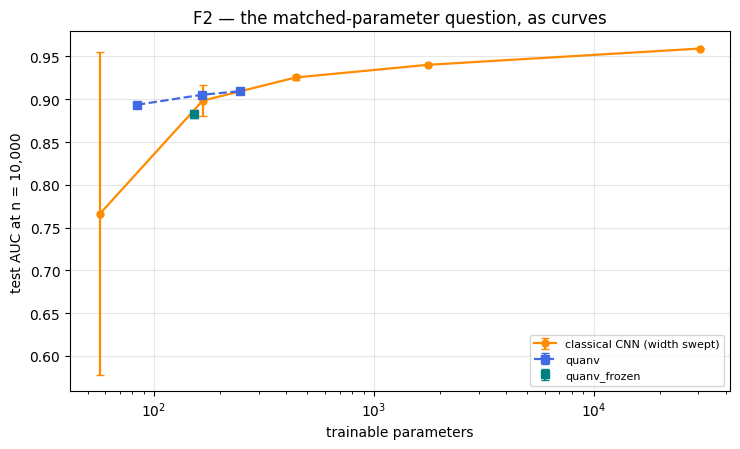

matched pair at n=10,000:  quanv w=2 (166 params) AUC 0.9053±0.0019   vs   cnn w=3 (167 params) AUC 0.8984±0.0184


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))

# classical curve: small CNN widths + the deep model
cw = [(w, stats("cnn", w, N_REF),
       run_or_load("cnn", w, N_REF, 0)["params"]) for w in (1, 3, 8, 32)]
cw.append((None, stats("cnn_deep", 16, N_REF), run_or_load("cnn_deep", 16, N_REF, 0)["params"]))
ax.errorbar([p for _, _, p in cw], [m for _, (m, _), _ in cw],
            yerr=[s for _, (_, s), _ in cw], marker="o", ms=5, capsize=3,
            color="darkorange", label="classical CNN (width swept)", lw=1.6)

# quantum curves: trained and frozen
for arm, col in (("quanv", "royalblue"), ("quanv_frozen", "teal")):
    widths = (1, 2, 3) if arm == "quanv" else (3,)
    pts = [(stats(arm, w, N_REF), run_or_load(arm, w, N_REF, 0)["params"]) for w in widths]
    ax.errorbar([p for _, p in pts], [m for (m, _), _ in pts],
                yerr=[s for (_, s), _ in pts], marker="s", ms=6, capsize=3,
                color=col, label=arm, lw=1.6, ls="--" if arm == "quanv" else "none")

ax.set_xscale("log")
ax.set_xlabel("trainable parameters"); ax.set_ylabel(f"test AUC at n = {N_REF:,}")
ax.set_title("F2 — the matched-parameter question, as curves")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

# the near-exact matched pair, printed explicitly
q2 = stats("quanv", 2, N_REF); c3 = stats("cnn", 3, N_REF)
print(f"matched pair at n={N_REF:,}:  quanv w=2 ({run_or_load('quanv',2,N_REF,0)['params']} params) "
      f"AUC {q2[0]:.4f}±{q2[1]:.4f}   vs   cnn w=3 ({run_or_load('cnn',3,N_REF,0)['params']} params) "
      f"AUC {c3[0]:.4f}±{c3[1]:.4f}")

### ✅ Reading F2 — the crossover is early at this configuration

The published claim (PRD version) is that classical needs ~100× the parameters to beat quantum.
Here the classical width-curve crosses the best quantum point **between 167 and 442 parameters**
(cnn w=8 at 442p scores 0.926 vs quanv w=3 at 248p scoring 0.910) — a factor of ~2, not 100.
Untuned, single configuration, so not a refutation — but a concrete marker the tuned study must
move or confirm.

**The matched pair** (printed above the figure): quanv w=2 (166p) 0.9053 ± 0.0019 vs cnn w=3
(167p) 0.8984 ± 0.0184. The central values favour the quantum arm by 0.007 — but that is well
inside the CNN's own seed spread, so with 3 seeds this is **not a detectable difference in mean
performance**. What *is* clearly different is the spread itself: ±0.002 vs ±0.018, a ~10×
reproducibility gap in the quantum arm's favour (and `cnn w=1`'s outright failed seed is the
extreme of the same phenomenon). If that pattern survives the tuned study, "quantum random
features make small models *reliable*" may be a more defensible claim than "make them *better*."


## 6. F3 — AUC vs label purity: the axis nobody else has

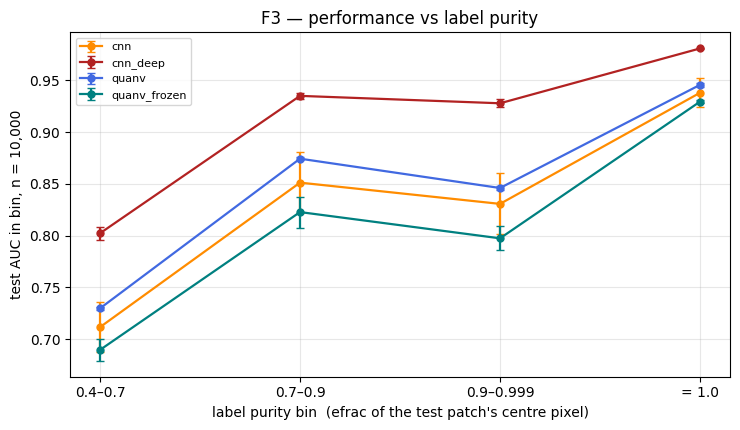

In [6]:
bins = (("bin_low", "0.4–0.7"), ("bin_mid", "0.7–0.9"),
        ("bin_high", "0.9–0.999"), ("bin_clean", "= 1.0"))
fig, ax = plt.subplots(figsize=(7.5, 4.4))
xs = np.arange(len(bins))
for arm, (col, w) in style.items():
    vals = np.array([[run_or_load(arm, w, N_REF, s)[b] for b, _ in bins] for s in SEEDS])
    ax.errorbar(xs, vals.mean(0), yerr=vals.std(0), marker="o", ms=5, capsize=3,
                color=col, label=arm, lw=1.6)
ax.set_xticks(xs, [lab for _, lab in bins])
ax.set_xlabel("label purity bin  (efrac of the test patch's centre pixel)")
ax.set_ylabel(f"test AUC in bin, n = {N_REF:,}")
ax.set_title("F3 — performance vs label purity")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

### ✅ Reading F3 — label purity moves AUC by ~0.2, for every arm

| arm | dirty (0.4–0.7) | clean (=1.0) | degradation |
|---|---|---|---|
| cnn_deep | 0.802 | 0.981 | **0.179** |
| quanv | 0.730 | 0.946 | 0.216 |
| cnn | 0.712 | 0.938 | 0.226 |
| quanv_frozen | 0.690 | 0.930 | 0.240 |

Three take-aways:

- **Label ambiguity is a first-order effect** — a fifth of an AUC between the cleanest and
  dirtiest bins. Any single quoted number for this task silently averages over it, which is why
  the plan makes purity a reporting axis rather than noise.
- **No sign that the quantum model degrades more gracefully under label noise** — if anything the
  deep CNN handles dirty labels best. One speculative motivation for QML robustness, tested and
  (at this configuration) not supported.
- **An unexplained wrinkle, left honest**: every arm scores slightly *lower* in the 0.9–0.999 bin
  than in 0.7–0.9. Purity bins differ in more than purity (topology mix, energy, class balance
  inside the bin), so this likely reflects bin composition — worth a look before the real study
  quotes this axis.

## 7. From here to the paper

This notebook is the study's machinery running end to end at reduced statistics. The gaps between
this and plan §2.3–2.5, in the order they should be closed:

1. **Equal-budget hyperparameter search** per arm per point — until then every gap above carries an
   unquantified "the fixed settings may suit one arm better."
2. **10+ seeds and bootstrap CIs over test events** — the 3-seed bars here understate uncertainty.
3. **Convergence audit at large n** — the fixed 2,500-step budget is ~3 epochs at n=100,000.
4. The remaining controls: capacity-matched regularised CNN, classical frozen random features
   (plan arms 5–6), and the reupload-convention sweep (§2.6).
5. Patch-size sweep (crop is a config change; the data is already 31×31).

The cache (`results/study04.jsonl`) is the start of the experiment log the real study needs —
every number above is reproducible from `(arm, width, n, seed)`.